Lab 04

Instructor Name: Attique-ur-Rehman

Student Name: Zoha Adnan

Sap Id: 70177706

In [2]:
# pip install pandas numpy scikit-learn matplotlib
import pandas as pd
import numpy as np

In [4]:
import os
print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\LENOVO
['.anaconda', '.cache', '.conda', '.condarc', '.continuum', '.gradio', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.streamlit', '.VirtualBox', '3D Objects', '70177706_zohaAdnan-sectionA.ipynb', 'anaconda3', 'app.py', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'dashboard.py', 'dashboard_project', 'data', 'Documents', 'Downloads', 'EDA project .ipynb', 'Favorites', 'First Program.ipynb', 'IntelGraphicsProfiles', 'Lab 2.ipynb', 'lab 6.ipynb', 'lab2 web scraping.ipynb', 'lab3 .ipynb', 'lab4.ipynb', 'Links', 'Local Settings', 'Math for ML .ipynb', 'Music', 'My Documents', 'my website.ipynb', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Prin

In [5]:
import os
for root, dirs, files in os.walk(r"C:\Users\LENOVO"):
    for f in files:
        if f.lower() in ("house_price_regression_dataset.csv", "diabetes.csv"):
            print(os.path.join(root, f))

C:\Users\LENOVO\Downloads\diabetes.csv
C:\Users\LENOVO\Downloads\house_price_regression_dataset.csv


In [6]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\house_price_regression_dataset.csv")
print(df.shape)
df.head()

(1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [7]:
print(df.isnull().sum())
print(df.describe())

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64
       Square_Footage  Num_Bedrooms  Num_Bathrooms   Year_Built     Lot_Size  \
count     1000.000000   1000.000000    1000.000000  1000.000000  1000.000000   
mean      2815.422000      2.990000       1.973000  1986.550000     2.778087   
std       1255.514921      1.427564       0.820332    20.632916     1.297903   
min        503.000000      1.000000       1.000000  1950.000000     0.506058   
25%       1749.500000      2.000000       1.000000  1969.000000     1.665946   
50%       2862.500000      3.000000       2.000000  1986.000000     2.809740   
75%       3849.500000      4.000000       3.000000  2004.250000     3.923317   
max       4999.000000      5.000000       3.000000  2022.000000     4.989303   

       Garage_Size  Neighborhood_Quality   House_Price  
c

In [8]:
from sklearn.model_selection import train_test_split

X = df[['Square_Footage','Num_Bedrooms','Num_Bathrooms','Year_Built',
        'Lot_Size','Garage_Size','Neighborhood_Quality']]
y = df['House_Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [10]:
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print(coef_df)
print("Intercept:", model.intercept_)

                Feature   Coefficient
0        Square_Footage    199.513245
1          Num_Bedrooms  10225.204426
2         Num_Bathrooms   8208.434772
3            Year_Built    993.537171
4              Lot_Size  14885.384415
5           Garage_Size   5146.148387
6  Neighborhood_Quality    115.068595
Intercept: -2010567.420101658


In [11]:
y_predict = model.predict(X_test)

In [12]:
results = pd.DataFrame({
    'Square_Footage': X_test['Square_Footage'].values,
    'Actual Price': y_test.values,
    'Predicted Price': y_predict
})
print(results.head(10))

   Square_Footage  Actual Price  Predicted Price
0            4012  9.010005e+05     8.686871e+05
1            2310  4.945375e+05     4.903379e+05
2            4708  9.494042e+05     9.456671e+05
3            4932  1.040389e+06     1.033403e+06
4            3646  7.940100e+05     7.766988e+05
5            3586  7.240336e+05     7.324441e+05
6            4638  9.984392e+05     9.950520e+05
7            4127  9.097134e+05     8.851748e+05
8            3781  7.926815e+05     7.967305e+05
9            4243  9.474908e+05     9.317411e+05


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae  = mean_absolute_error(y_test, y_predict)
mse  = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_predict)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 8174.583599866788
MSE : 101434798.45037074
RMSE: 10071.48442139344
R2  : 0.9984263636832063


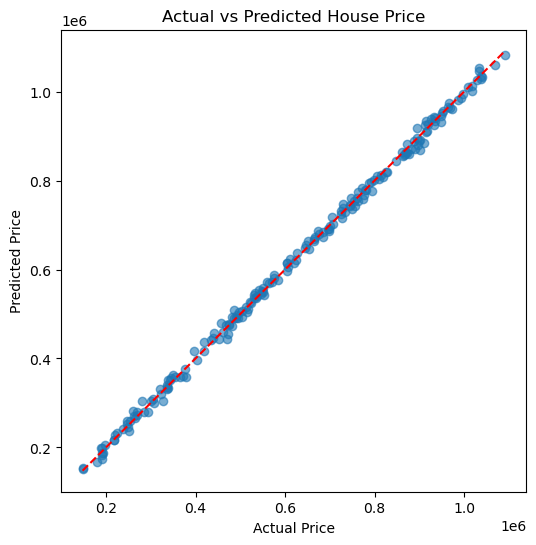

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_predict, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Price")
plt.show()

In [15]:
new_house = pd.DataFrame([[2500, 3, 2, 2005, 2.5, 1, 7]], columns=X.columns)
print("Predicted price:", model.predict(new_house)[0])

Predicted price: 570515.2928711125
